# 04_GEFS_Download - Dự báo thời tiết 7 ngày GEFSv12 reforecast gộp về 451 lưu vực Extended LamaH-CE, làm đầu vào
# cho cách gefs của bước H (02_Pipeline.md Mục 4.4).
# Nguồn: NOAA GEFSv12 reforecast (Guan và cs., Monthly Weather Review 150, 2022), AWS noaa-gefs-retrospective: khởi tạo
# 00 UTC hằng ngày 2000-2019, 5 thành viên (c00, p01-p04), lưới 0,25 độ, bước 3 giờ trong 10 ngày đầu; giấy phép NOAA
# NODD (dùng tự do, ghi nguồn). Ngày dự báo tính từ 00 UTC như ECMWF HRES của Extended LamaH-CE (BiasCast: trung bình
# ngày từ lúc phát 00 UTC).
# Đầu ra: gefs_<năm>.npz (5 biến + mưa c00, [ngày khởi tạo, 7 hạn, 451 lưu vực]) và gefs_lamah_daily.npz (35 cột
# GEFS_<biến>_lead<k>: giá trị tại ngày d là dự báo cho ngày d phát từ ngày d-k+1; [451, 01/01/2003..31/12/2017, 35]).
# Cài đặt: Accelerator = None (CPU), Internet = On, Persistence = Files only, Add Input => lamah-ce-ext.
# Dán nguyên tệp rồi Save & Run All, không sửa dòng nào. Phần 3 dừng trước 11 giờ nếu chưa xong: tạo notebook
# 04_GEFS_Download_Cont cùng mã, thêm Input = Output phiên trước => các năm đã có được chép lại, chỉ tải năm còn thiếu.
#
# MỤC LỤC
#   Phần 1 - Thư viện, hằng số, lưu vực, trọng số ô lưới
#   Phần 2 - Kiểm đường tải và giải mã song song trên 2 ngày khởi tạo
#   Phần 3 - Tải, giải mã, gộp theo năm
#   Phần 4 - Dựng 35 cột theo hạn, kiểm độ phủ, so với tái phân tích và ECMWF HRES
#   Phần 5 - Tóm tắt, danh mục tệp

mục,giá trị
shapefile,"A_basins_total_upstrm/3_shapefiles/Basins_A.shp (cột ID, EPSG:3035)"
vùng cắt,"vĩ độ 50.5..46.0, kinh độ 7.75..17.5 (19 x 40 ô)"
ô mỗi lưu vực (nhỏ nhất / trung vị / lớn nhất),1 / 2 / 54
phần lưu vực nằm trong vùng lưới (nhỏ nhất),1.000000
CPU,"4 nhân, Python 3.13.15"


kiểm,đạt
pygrib 2.1.8,ĐẠT
"451 lưu vực khác nhau, có trong shapefile",ĐẠT
shapefile EPSG:3035,ĐẠT
"mỗi lưu vực nằm trọn trong vùng lưới (phần giao / diện tích >= 0,999)",ĐẠT
mỗi lưu vực có ít nhất 1 ô,ĐẠT


kiểm,đạt
"lưới bản tin = lưới Phần 1 (90..-90 x 0..359,75, bước 0,25)",ĐẠT
giải mã song song = tuần tự (lệch lớn nhất 0),ĐẠT
"không có ô trống, mưa >= 0, bức xạ >= 0",ĐẠT


2 ngày khởi tạo song song: 12 giây (373 MB)
Năm có sẵn: 16/16 (chép từ Input: [2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017]); chờ tải 0 phút, chờ giải mã 0 phút


biến,so với,GEFS hạn 1,GEFS hạn 2,GEFS hạn 3,GEFS hạn 4,GEFS hạn 5,GEFS hạn 6,GEFS hạn 7,ECMWF HRES hạn 1
t2m,ERA5L_2m_temp_mean,0.991,0.9902,0.9886,0.9851,0.9789,0.9665,0.9508,0.9945
d2m,ERA5L_2m_dp_temp_mean,0.9873,0.9868,0.9845,0.9785,0.9697,0.9513,0.9307,0.9939
ssrd,EOBS_qq,0.9398,0.9324,0.9126,0.8944,0.8543,0.8104,0.7601,0.9551
tp,MSWEP_RR,0.8246,0.7806,0.7357,0.669,0.5866,0.4889,0.3776,0.8286
e,GLEAM_ETA,0.9029,0.896,0.8837,0.8746,0.8531,0.8332,0.8088,0.9104
tp c00 (1 thành viên),MSWEP_RR,0.8182,0.7514,0.6887,0.6192,0.5162,0.4139,0.2768,nan


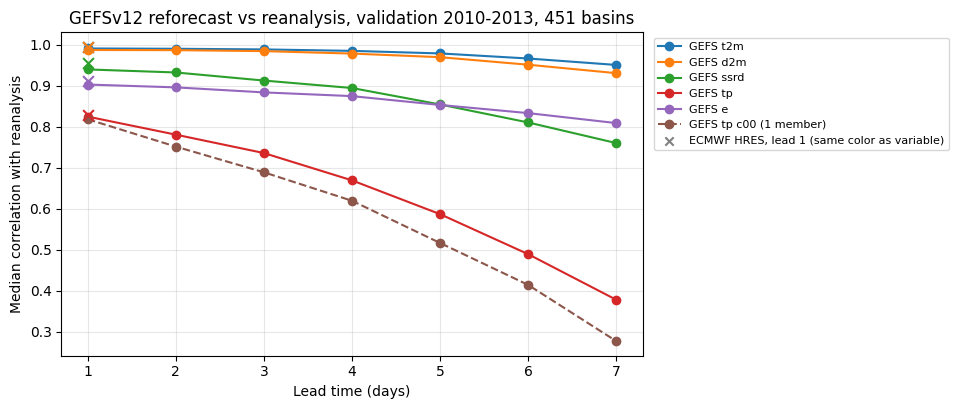

Hình: tương quan trung vị theo hạn (451 lưu vực, validation 2010-2013) của 5 biến GEFS (đường) và ECMWF HRES hạn 1 (dấu x) với biến tái phân tích tương ứng: mưa với MSWEP_RR, nhiệt độ và điểm sương với ERA5-Land, bức xạ với E-OBS, bốc hơi với GLEAM. Mưa GEFS trung bình 5 thành viên: hạn 1 0.825 (ECMWF HRES 0.829), hạn 7 0.378.


biến,nhỏ nhất,trung vị,lớn nhất,ô trống
t2m,-29.23,6.519,29.98,0
d2m,-31.89,3.891,21.12,0
ssrd,0,130.8,381.5,6765
tp,0,1.544,129.1,6314
e,-0.993,1.434,8.359,451
tp_c00,0,0.9011,149.8,0


Điểm sương - nhiệt độ: lớn nhất 1.21 °C; ô > 0: 66655 (0.38%); ô > 1 °C: 22 / 17316145


kiểm,đạt
"đủ 5485 ngày khởi tạo 2002-12-26..2017-12-31, liền mạch",ĐẠT
"35 cột x 5479 ngày x 451 lưu vực, ô trống đúng chỗ KNOWN_GAPS",ĐẠT
"mưa >= 0, bức xạ >= 0",ĐẠT
"nhiệt độ trong -40..40 °C, điểm sương <= nhiệt độ + 2 °C, ô điểm sương > nhiệt độ < 1%",ĐẠT
hạn 1 cột lead1 = mảng gốc (ngày khởi tạo = ngày đích),ĐẠT


tệp,MB,sha256
figures/GEFS_Skill_by_Lead.png,0.1573,e3a200b6571c317de8a9b6192e37541623d1102cd88252fdb8d6a1f0149c60df
gefs/gefs_2002.npz,0.4622,c0650561798a4e9a16ea613c569ee50a5cb693f58f6621a09b856eb3431c9fee
gefs/gefs_2003.npz,27.68,9044c2b1da591e2c227492fbf1677de8605c152d76d4c06ddadcdc7217d08734
gefs/gefs_2004.npz,27.75,fa058592358c3910457c143b9c01d3a14cbe29439da89b9c84b051de1dd77fb7
gefs/gefs_2005.npz,27.68,a2c14f91ba8d017704a56925bbce7753d6e8e514add2009c30c7ed7ce2bdd40b
gefs/gefs_2006.npz,27.68,a745a500b6df5cd7d899e5d79bbcc0fcfe707ac2b49fc674a34956c8ec51fd02
gefs/gefs_2007.npz,27.68,be1e81355e06d7c5934c8b41e55df28a0c80dc3e317f965d77b6061bc7894338
gefs/gefs_2008.npz,27.75,288c905760c2427cd05785cb6e6c01e558fd5d87a51a7664dd2fa01fbd67b4dd
gefs/gefs_2009.npz,27.68,91255f74bc53697594ee02c135af6d29f5afa9e08b2af53f05cd39288963f4bb
gefs/gefs_2010.npz,27.68,94fb9d245f77f8744de7f57e25e3cf04c35c861553bdb7910dab031bf2ae4806


XONG: 0.06 giờ.


In [1]:
# %% Phần 1 - Thư viện, hằng số, lưu vực, trọng số ô lưới
# (1) pygrib 2.1.8 (wheel manylinux có sẵn ecCodes); geopandas có sẵn trên Kaggle, thiếu thì cài.
# (2) Lưu vực: shapefile A_basins_total_upstrm/3_shapefiles/Basins_A.shp (cột ID, EPSG:3035), 451 lưu vực của
#     basins_filtered.txt. (3) Trọng số = diện tích phần giao ô lưới 0,25 độ / diện tích lưu vực, tính ở EPSG:3035.
import hashlib, html, json, multiprocessing as mp, os, platform, re, shutil, subprocess, sys, time, urllib.parse
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from IPython.display import HTML, display

T0 = time.time()
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pygrib==2.1.8"], check=True)
try:
    import geopandas as gpd
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "geopandas"], check=True)
    import geopandas as gpd
import pygrib
from shapely.geometry import box

S3 = "https://noaa-gefs-retrospective.s3.amazonaws.com"
ROOT = "GEFSv12/reforecast"
INPUT = Path("/kaggle/input")
WORK = Path("/kaggle/working")
OUT = WORK / "gefs"
FIG = WORK / "figures"
FIRST_INIT, LAST_INIT = pd.Timestamp("2002-12-26"), pd.Timestamp("2017-12-31")
TARGET = pd.date_range("2003-01-01", "2017-12-31")     # ngày có đủ 7 hạn: train 2003-2009, validation, test tới 2017
VAL = (pd.Timestamp("2010-01-01"), pd.Timestamp("2013-12-31"))
HORIZON = 7
LEADS = range(1, HORIZON + 1)
INST_FILES = ("tmp_2m", "spfh_2m", "pres_sfc")   # giá trị tức thời 3 giờ; các tệp khác tích lũy/trung bình 6 giờ
MEMBERS = ("c00", "p01", "p02", "p03", "p04")
C00_FILES = ("apcp_sfc", "tmp_2m", "spfh_2m", "pres_sfc", "dswrf_sfc", "lhtfl_sfc")
JOBS = [(v, "c00") for v in C00_FILES] + [("apcp_sfc", m) for m in MEMBERS[1:]]
GRIB_NAME = {"apcp_sfc": "APCP", "tmp_2m": "TMP", "spfh_2m": "SPFH", "pres_sfc": "PRES", "dswrf_sfc": "DSWRF",
             "lhtfl_sfc": "LHTFL"}
# Biến đầu ra, cùng thứ tự với 5 biến ECMWF HRES (t2m, d2m, ssrd, tp, e) và 5 biến tái phân tích của cách perfect
GEFS_VARS = ("t2m", "d2m", "ssrd", "tp", "e")
ECMWF_OF = {"t2m": "ECMWF_t2m", "d2m": "ECMWF_d2m", "ssrd": "ECMWF_ssrd", "tp": "ECMWF_tp", "e": "ECMWF_e"}
REANALYSIS_OF = {"t2m": "ERA5L_2m_temp_mean", "d2m": "ERA5L_2m_dp_temp_mean", "ssrd": "EOBS_qq", "tp": "MSWEP_RR",
                 "e": "GLEAM_ETA"}          # LAMAH_PERFECT_FORECAST (source_groups.py ở freeze-H)
STORE = GEFS_VARS + ("tp_c00",)              # tp = trung bình 5 thành viên; tp_c00 chỉ để kiểm
# Chỗ thiếu đã biết (quét .idx, trường ENS và danh sách tệp S3 của mọi tệp cần 2002-2017), giá trị = (biến lưu, các
# hạn để trống):
# - khởi tạo 08/05/2005 bức xạ, ẩn nhiệt c00 thiếu bản tin 0-3, 0-6 giờ => hạn 1 trống;
# - SKIP_FILES: tệp không dùng được => cả 7 hạn trống. "missing" = .grib2 không có trên kho (còn .idx); "copy" = tệp
#   của thành viên này là bản chép của thành viên khác (.idx ghi ENS của thành viên đó, cùng ETag).
#   tp là trung bình 5 thành viên: thiếu hay chép một thành viên => tp trống, không lấy trung bình các thành viên còn
#   lại, để mọi ô cùng một định nghĩa.
# Masked mean ở mô hình bỏ nhóm GEFS của hạn có ô trống; chỗ thiếu khác => dừng.
SKIP_FILES = {("2004-11-09", "dswrf_sfc", "c00"): "missing", ("2006-02-08", "dswrf_sfc", "c00"): "missing",
              ("2006-09-15", "apcp_sfc", "p01"): "missing",
              ("2006-10-01", "apcp_sfc", "p02"): "copy ENS=+1", ("2006-10-01", "apcp_sfc", "p03"): "copy ENS=+1",
              ("2006-10-01", "apcp_sfc", "p04"): "copy ENS=+1"}
SKIP_VAR = {"tmp_2m": "t2m", "spfh_2m": "d2m", "pres_sfc": "d2m", "dswrf_sfc": "ssrd", "apcp_sfc": "tp", "lhtfl_sfc": "e"}
KNOWN_GAPS = {("2005-05-08", "dswrf_sfc", "c00"): ("ssrd", (1,)), ("2005-05-08", "lhtfl_sfc", "c00"): ("e", (1,)),
              **{key: (SKIP_VAR[key[1]], tuple(LEADS)) for key in SKIP_FILES}}
NEG_TOL = 1e-3                               # mưa, bức xạ: cho phép âm tới -0,001 do sai số nén GRIB
DEW_TOL, DEW_FRAC = 2.0, 0.01                # điểm sương tính từ trung bình ngày, lưu vực của độ ẩm riêng, áp suất có thể
                                             # vượt nhiệt độ trung bình chút ít (Magnus phi tuyến); lỗi đơn vị, công thức
                                             # => vượt hàng chục độ hoặc ở phần lớn ô
LV = 2.501e6                                 # nhiệt ẩn hóa hơi (J/kg) => mm/ngày = W/m2 * 86400 / LV
LIMIT_H = 11.0                               # giới hạn phiên Kaggle 12 giờ, chừa 1 giờ cho Phần 4-5
THREADS, PREFETCH = 20, 4                    # luồng tải; số ngày khởi tạo tải trước
N_PROC = os.cpu_count()
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)


def show(title, df):
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index").format({c: "{:.4g}" for c in df.select_dtypes("float").columns}))


def caption(text):
    print(f"Hình: {text}")


def find_one(pattern, kind):
    hits = sorted(p for p in INPUT.rglob(pattern) if (p.is_dir() if kind == "dir" else p.is_file()))
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng 1 {pattern} dưới {INPUT}, thấy {len(hits)}: {hits}")
    return hits[0]


LAMAH_DIR = find_one("LamaH_extended", "dir")
basins = find_one("basins_filtered.txt", "file").read_text().split()
SHP = LAMAH_DIR / "A_basins_total_upstrm" / "3_shapefiles" / "Basins_A.shp"
shp = gpd.read_file(SHP)
shp_ids = shp["ID"].astype(str).str.replace(r"\.0$", "", regex=True)
geo = shp.assign(basin=shp_ids).drop_duplicates("basin").set_index("basin").loc[basins, ["geometry"]]
geo_ll, geo_ea = geo.to_crs(4326), geo.to_crs(3035)

# Lưới GEFSv12 0,25 độ: vĩ độ 90 => -90 (721), kinh độ 0 => 359,75 (1440); Phần 2 đối chiếu với bản tin thật
LAT = 90 - 0.25 * np.arange(721)
LON = 0.25 * np.arange(1440)
x0, y0, x1, y1 = geo_ll.total_bounds
rows = np.where((LAT >= y0 - 0.5) & (LAT <= y1 + 0.5))[0]
cols = np.where((LON >= x0 - 0.5) & (LON <= x1 + 0.5))[0]
GRID = (int(rows.min()), int(rows.max()) + 1, int(cols.min()), int(cols.max()) + 1)
la, lo = np.meshgrid(LAT[GRID[0]:GRID[1]], LON[GRID[2]:GRID[3]], indexing="ij")
cells = gpd.GeoDataFrame({"cell": np.arange(la.size)}, crs=4326, geometry=[
    box(x - 0.125, y - 0.125, x + 0.125, y + 0.125) for y, x in zip(la.ravel(), lo.ravel())]).to_crs(3035)
inter = gpd.overlay(geo_ea.reset_index(), cells, how="intersection")
W = np.zeros((len(basins), la.size))
np.add.at(W, (inter["basin"].map({b: i for i, b in enumerate(basins)}).to_numpy(), inter["cell"].to_numpy()),
          inter.area.to_numpy())
COVER = W.sum(1) / geo_ea.area.to_numpy()
W /= W.sum(1, keepdims=True)
N_CELLS = (W > 0).sum(1)

checks1 = {
    "pygrib 2.1.8": pygrib.__version__ == "2.1.8",
    "451 lưu vực khác nhau, có trong shapefile": len(set(basins)) == 451 and set(basins) <= set(shp_ids),
    "shapefile EPSG:3035": shp.crs.to_epsg() == 3035,
    "mỗi lưu vực nằm trọn trong vùng lưới (phần giao / diện tích >= 0,999)": bool(COVER.min() >= 0.999),
    "mỗi lưu vực có ít nhất 1 ô": bool(N_CELLS.min() >= 1),
}
show("Lưu vực và trọng số ô lưới", pd.DataFrame([
    ("shapefile", f"{SHP.relative_to(LAMAH_DIR)} (cột ID, EPSG:{shp.crs.to_epsg()})"),
    ("vùng cắt", f"vĩ độ {la.max()}..{la.min()}, kinh độ {lo.min()}..{lo.max()} ({la.shape[0]} x {la.shape[1]} ô)"),
    ("ô mỗi lưu vực (nhỏ nhất / trung vị / lớn nhất)", f"{N_CELLS.min()} / {int(np.median(N_CELLS))} / {N_CELLS.max()}"),
    ("phần lưu vực nằm trong vùng lưới (nhỏ nhất)", f"{COVER.min():.6f}"),
    ("CPU", f"{N_PROC} nhân, Python {platform.python_version()}"),
], columns=["mục", "giá trị"]))
show("Kiểm Phần 1", pd.DataFrame({"kiểm": list(checks1), "đạt": ["ĐẠT" if v else "KHÔNG" for v in checks1.values()]}))
if not all(checks1.values()):
    raise RuntimeError("Phần 1 CHƯA đạt")


# %% Phần 2 - Kiểm đường tải và giải mã song song trên 2 ngày khởi tạo
# (1) Mỗi tệp: đọc .idx, chọn bản tin theo mô tả (tức thời: 3..168 giờ, 56 bản tin; tích lũy/trung bình: các khoảng
#     6 giờ 0-6..162-168, 28 bản tin), tải liền một đoạn từ đầu tệp tới bản tin cần cuối cùng (HTTP Range), kiểm tên
#     biến, ngày khởi tạo, thành viên, số byte. Bản tin ghi trùng (VD mưa c00 khởi tạo 11/04/2003 ghi hai lần từ giờ 72)
#     phải trùng từng byte, lấy bản đầu.
# (2) Giải mã trong N_PROC tiến trình (fork, tạo trước khi mở luồng tải), mỗi bản tin => trung bình 451 lưu vực.
# (3) Gộp theo ngày: tổng 4 bản tin 6 giờ (acc), trung bình 4 bản tin 6 giờ (ave), trung bình 8 bản tin tức thời 3 giờ.
# (4) Hai ngày khởi tạo giải mã song song phải trùng từng bit giải mã tuần tự; lưới bản tin trùng lưới Phần 1.
def get(url, rng=None, tries=8):
    # Thử lại tới 8 lần, chờ 1, 2, 4 ... 60 giây (tổng khoảng 3 phút): lỗi mạng, mã lỗi HTTP, đoạn tải thiếu byte
    for k in range(tries):
        try:
            r = requests.get(url, headers={"Range": f"bytes={rng[0]}-{rng[1]}"} if rng else {}, timeout=180)
            r.raise_for_status()
            if rng and (r.status_code != 206 or len(r.content) != rng[1] - rng[0] + 1):
                raise requests.RequestException(f"mã {r.status_code}, {len(r.content)} byte, cần {rng[1] - rng[0] + 1}")
            return r.content
        except requests.RequestException as e:
            if k == tries - 1:
                raise RuntimeError(f"{url}: hỏng sau {tries} lần thử ({e})")
            time.sleep(min(2 ** k, 60))


def s3_dirs(prefix):
    out, token = [], None
    while True:
        p = {"list-type": "2", "prefix": prefix, "delimiter": "/"}
        if token:
            p["continuation-token"] = token
        txt = get(S3 + "/?" + urllib.parse.urlencode(p)).decode()
        out += [x for x in re.findall(r"<Prefix>([^<]*)</Prefix>", txt) if x != prefix]
        m = re.search(r"<NextContinuationToken>([^<]*)</NextContinuationToken>", txt)
        if not m:
            return out
        token = html.unescape(m[1])


def wanted(var):
    # Mô tả các bản tin cần cho 7 ngày từ 00 UTC, theo thứ tự thời gian
    if var in INST_FILES:
        return [f"{h} hour fcst" for h in range(3, 24 * HORIZON + 1, 3)]
    kind = "acc" if var == "apcp_sfc" else "ave"
    return [f"{a}-{a + 6} hour {kind} fcst" for a in range(0, 24 * HORIZON, 6)]


def fetch(date, var, member):
    url = f"{S3}/{ROOT}/{date:%Y}/{date:%Y%m%d}00/{member}/Days:1-10/{var}_{date:%Y%m%d}00_{member}.grib2"
    skip = SKIP_FILES.get((f"{date:%Y-%m-%d}", var, member))
    if skip == "missing":
        # Tệp không có trên kho => mọi bản tin None (NaN cả 7 hạn); kho có lại tệp thì dừng để cập nhật danh sách
        code = None
        for k in range(8):
            try:
                code = requests.head(url, timeout=60).status_code
                break
            except requests.RequestException:
                if k == 7:
                    raise
                time.sleep(min(2 ** k, 60))
        if code != 404:
            raise RuntimeError(f"{url}: ghi là missing nhưng kho trả mã {code}")
        return wanted(var), [None] * len(wanted(var))
    if skip is not None:
        # Bản chép của thành viên khác: .idx phải vẫn ghi ENS đó ở mọi dòng, sửa rồi thì dừng để cập nhật danh sách
        other = skip.split()[1]
        labels = {line.split(":")[6] for line in get(url + ".idx").decode().strip().splitlines()}
        if labels != {other}:
            raise RuntimeError(f"{url}: ghi là {skip} nhưng .idx có ENS {labels}")
        return wanted(var), [None] * len(wanted(var))
    idx =[line.split(":") for line in get(url + ".idx").decode().strip().splitlines()]
    ens = "ENS=low-res ctl" if member == "c00" else f"ENS=+{int(member[1:])}"
    want = wanted(var)
    pos = {w: [i for i, r in enumerate(idx) if r[5] == w] for w in want}
    miss = [w for w, ix in pos.items() if not ix]
    use = sorted(i for ix in pos.values() for i in ix)
    bad = [idx[i] for i in use if idx[i][2] != f"d={date:%Y%m%d}00" or idx[i][3] != GRIB_NAME[var] or idx[i][6] != ens]
    gap_ok = (f"{date:%Y-%m-%d}", var, member) in KNOWN_GAPS and len(miss) < len(want)
    if (miss and not gap_ok) or bad or use[-1] >= len(idx) - 1:
        raise RuntimeError(f"{url}: .idx {len(idx)} dòng, thiếu {miss[:2]}, dòng lạ {bad[:1]}")
    offs = [int(r[1]) for r in idx]
    data = get(url, (0, offs[use[-1] + 1] - 1))
    msgs = []
    for w in want:
        if not pos[w]:
            msgs.append(None)               # bản tin thiếu (chỉ ở KNOWN_GAPS) => NaN ở các hạn cần nó
            continue
        copies = {data[offs[i]:offs[i + 1]] for i in pos[w]}
        if len(copies) != 1:
            raise RuntimeError(f"{url}: bản tin {w} ghi {len(pos[w])} lần, nội dung khác nhau")
        msgs.append(copies.pop())
    return want, msgs


def decode_file(msgs):
    # Chạy trong tiến trình con: bản tin GRIB => [số bản tin, 451] trung bình lưu vực (float64)
    return np.stack([np.full(W.shape[0], np.nan) if b is None else
                     W @ np.asarray(pygrib.fromstring(b).values, dtype=np.float64)[GRID[0]:GRID[1], GRID[2]:GRID[3]]
                     .ravel() for b in msgs])


def daily(descs, fields):
    out = np.full((HORIZON, fields.shape[1]), np.nan)
    for d in LEADS:
        lo_h, hi_h = 24 * (d - 1), 24 * d
        pick, kind = [], "inst"
        for i, s in enumerate(descs):
            m = re.match(r"(\d+)-(\d+) hour (acc|ave) fcst", s)
            if m:
                kind = m[3]
                a, b = int(m[1]), int(m[2])
                if b - a == 6 and a % 6 == 0 and lo_h <= a < hi_h:
                    pick.append(i)
            else:
                m = re.match(r"(\d+) hour fcst", s)
                if m and lo_h < int(m[1]) <= hi_h:
                    pick.append(i)
        if len(pick) != (8 if kind == "inst" else 4):
            raise RuntimeError(f"Hạn {d}: chọn {len(pick)} bản tin ({kind}), mẫu {descs[:3]}")
        out[d - 1] = fields[pick].sum(0) if kind == "acc" else fields[pick].mean(0)
    return out


def derive(day):
    # day[(tệp, thành viên)] = [7, 451] => 6 biến lưu
    q, p = day[("spfh_2m", "c00")], day[("pres_sfc", "c00")]
    ev = np.log(q * p / (0.622 + 0.378 * q) / 611.2)      # áp suất hơi / 611,2 Pa (Magnus, Alduchov & Eskridge 1996)
    return {"t2m": day[("tmp_2m", "c00")] - 273.15,
            "d2m": 243.12 * ev / (17.62 - ev),
            "ssrd": day[("dswrf_sfc", "c00")],
            "tp": np.mean([day[("apcp_sfc", m)] for m in MEMBERS], axis=0),
            "e": day[("lhtfl_sfc", "c00")] * 86400 / LV,
            "tp_c00": day[("apcp_sfc", "c00")]}


POOL = mp.get_context("fork").Pool(N_PROC)  # trước khi mở luồng tải
DL = ThreadPoolExecutor(THREADS)
STAT = {"bytes": 0, "t_wait_dl": 0.0, "t_wait_dec": 0.0}


def run_inits(dates):
    # Tải trước PREFETCH ngày khởi tạo; giải mã ngày i trong lúc tải ngày i+1..i+PREFETCH; trả {ngày: 6 biến}
    dates = list(dates)
    dl, out, pending = {}, {}, None

    def submit(d):
        dl[d] = [DL.submit(fetch, d, v, m) for v, m in JOBS]

    def collect(item):
        d, parts = item
        t = time.time()
        day = {job: daily(descs, res.get()) for job, (descs, res) in zip(JOBS, parts)}
        STAT["t_wait_dec"] += time.time() - t
        out[d] = derive(day)

    for d in dates[:PREFETCH]:
        submit(d)
    for i, d in enumerate(dates):
        if i + PREFETCH < len(dates):
            submit(dates[i + PREFETCH])
        t = time.time()
        files = [f.result() for f in dl.pop(d)]
        STAT["t_wait_dl"] += time.time() - t
        STAT["bytes"] += sum(len(b) for _, msgs in files for b in msgs if b is not None)
        parts = [(descs, POOL.apply_async(decode_file, (msgs,))) for descs, msgs in files]
        if pending is not None:
            collect(pending)
        pending = (d, parts)
    if pending is not None:
        collect(pending)
    return out


t = time.time()
probe = [pd.Timestamp("2010-07-15"), pd.Timestamp("2016-02-29")]
par = run_inits(probe)
t_probe = time.time() - t
seq_max, grid_ok = 0.0, True
for d in probe:
    files = [fetch(d, v, m) for v, m in JOBS]
    g = pygrib.fromstring(files[0][1][0])
    lats, lons = g.latlons()
    grid_ok &= lats.shape == (len(LAT), len(LON)) and np.allclose(lats[:, 0], LAT, atol=1e-6)         and np.allclose(lons[0, :], LON, atol=1e-6)
    day = {job: daily(descs, decode_file(msgs)) for job, (descs, msgs) in zip(JOBS, files)}
    seq = derive(day)
    seq_max = max(seq_max, max(float(np.abs(seq[k] - par[d][k]).max()) for k in STORE))
checks2 = {
    "lưới bản tin = lưới Phần 1 (90..-90 x 0..359,75, bước 0,25)": bool(grid_ok),
    "giải mã song song = tuần tự (lệch lớn nhất 0)": seq_max == 0.0,
    "không có ô trống, mưa >= 0, bức xạ >= 0": all(np.isfinite(par[d][k]).all() for d in probe for k in STORE)
        and all((par[d][k] >= -NEG_TOL).all() for d in probe for k in ("tp", "tp_c00", "ssrd")),
}
show("Kiểm Phần 2", pd.DataFrame({"kiểm": list(checks2), "đạt": ["ĐẠT" if v else "KHÔNG" for v in checks2.values()]}))
print(f"2 ngày khởi tạo song song: {t_probe:.0f} giây ({STAT['bytes'] / 1e6:.0f} MB)")
if not all(checks2.values()):
    raise RuntimeError("Phần 2 CHƯA đạt")


# %% Phần 3 - Tải, giải mã, gộp theo năm (gefs_<năm>.npz trong /kaggle/working/gefs)
# Năm đã có trong Input (Output phiên trước) được chép sang, không tải lại. Trước mỗi năm, nếu thời gian đã chạy + thời
# gian dự kiến của năm vượt LIMIT_H giờ thì dừng gọn (chạy notebook _Cont).
def year_inits(y):
    days = {x.rstrip("/").split("/")[-1][:8] for x in s3_dirs(f"{ROOT}/{y}/")}
    want = pd.date_range(max(FIRST_INIT, pd.Timestamp(y, 1, 1)), min(LAST_INIT, pd.Timestamp(y, 12, 31)))
    miss = [d for d in want if d.strftime("%Y%m%d") not in days]
    if miss:
        raise RuntimeError(f"Năm {y}: kho thiếu {len(miss)} ngày khởi tạo, ví dụ {miss[:3]}")
    return want


YEARS = list(range(FIRST_INIT.year, LAST_INIT.year + 1))
reused = []
for y in YEARS:
    prev = sorted(p for p in INPUT.rglob(f"gefs_{y}.npz") if OUT not in p.parents)
    if prev and not (OUT / f"gefs_{y}.npz").exists():
        shutil.copy2(prev[0], OUT / f"gefs_{y}.npz")
        reused.append(y)

STAT.update(bytes=0, t_wait_dl=0.0, t_wait_dec=0.0)
rate, rows_y, paused = None, [], False         # rate: giây/ngày khởi tạo đo được
for y in YEARS:
    f = OUT / f"gefs_{y}.npz"
    if f.exists():
        continue
    inits = year_inits(y)
    need_h = (rate or 6.0) * len(inits) / 3600
    if (time.time() - T0) / 3600 + need_h > LIMIT_H:
        paused = True
        print(f"Dừng trước năm {y}: đã chạy {(time.time() - T0) / 3600:.2f} giờ, năm {y} cần khoảng {need_h:.2f} giờ "
              f"=> chạy notebook 04_GEFS_Download_Cont (thêm Input = Output phiên này)", flush=True)
        break
    t, b0 = time.time(), STAT["bytes"]
    res = run_inits(inits)
    arr = {k: np.stack([res[d][k] for d in inits]).astype(np.float32) for k in STORE}
    allow = {k: np.zeros(v.shape, bool) for k, v in arr.items()}
    for (gd, _, _), (k, leads) in KNOWN_GAPS.items():
        if pd.Timestamp(gd) in inits:
            allow[k][inits.get_loc(pd.Timestamp(gd)), [l - 1 for l in leads], :] = True
    bad = {k: int((~np.isfinite(v) & ~allow[k]).sum()) for k, v in arr.items()}
    if any(bad.values()) or any(np.isfinite(arr[k][allow[k]]).any() for k in arr):
        raise RuntimeError(f"Năm {y}: ô trống ngoài KNOWN_GAPS {bad}, hoặc ô KNOWN_GAPS lại có số")
    np.savez(f.with_suffix(".tmp.npz"), inits=np.array(inits.strftime("%Y-%m-%d"), dtype=str), basins=np.array(basins, dtype=str), **arr)
    f.with_suffix(".tmp.npz").rename(f)
    dt = time.time() - t
    rate = dt / len(inits)
    rows_y.append({"năm": y, "ngày khởi tạo": len(inits), "GB tải": (STAT["bytes"] - b0) / 1e9, "phút": dt / 60,
                   "giây/ngày khởi tạo": rate, "đã chạy (giờ)": (time.time() - T0) / 3600})
    print(f"{y}: {len(inits)} ngày khởi tạo, {(STAT['bytes'] - b0) / 1e9:.1f} GB, {dt / 60:.1f} phút, "
          f"tổng {(time.time() - T0) / 3600:.2f} giờ", flush=True)
DL.shutdown()
POOL.close()
POOL.join()
if rows_y:
    show("Theo năm (phiên này)", pd.DataFrame(rows_y))
done = [y for y in YEARS if (OUT / f"gefs_{y}.npz").exists()]
print(f"Năm có sẵn: {len(done)}/{len(YEARS)} (chép từ Input: {reused or 'không'}); chờ tải {STAT['t_wait_dl'] / 60:.0f} "
      f"phút, chờ giải mã {STAT['t_wait_dec'] / 60:.0f} phút")


# %% Phần 4 - Dựng 35 cột theo hạn, kiểm độ phủ, so với tái phân tích và ECMWF HRES (chỉ khi đủ mọi năm)
# Cột GEFS_<biến>_lead<k> tại ngày d = dự báo cho ngày d phát lúc 00 UTC ngày d-k+1, thứ tự hạn 1..7, trong mỗi hạn
# t2m, d2m, ssrd, tp, e. So sánh: tương quan theo từng lưu vực trên kỳ validation 2010-2013, trung vị qua 451 lưu vực.
COLUMNS = [f"GEFS_{v}_lead{k}" for k in LEADS for v in GEFS_VARS]
summary = {"complete": len(done) == len(YEARS), "years_done": done, "years_reused": reused, "paused": paused}
if summary["complete"]:
    parts = [np.load(OUT / f"gefs_{y}.npz") for y in YEARS]
    if any(list(p["basins"]) != basins for p in parts):
        raise RuntimeError("Thứ tự lưu vực trong gefs_<năm>.npz khác basins_filtered.txt")
    inits = pd.DatetimeIndex(np.concatenate([p["inits"] for p in parts]))
    A = {k: np.concatenate([p[k] for p in parts]) for k in STORE}
    pos = pd.Series(np.arange(len(inits)), index=inits)
    VALUES = np.full((len(basins), len(TARGET), len(COLUMNS)), np.nan, dtype=np.float32)
    for k in LEADS:
        src = pos.reindex(TARGET - pd.Timedelta(days=k - 1))
        if src.isna().any():
            raise RuntimeError(f"Hạn {k}: thiếu {int(src.isna().sum())} ngày khởi tạo")
        for j, v in enumerate(GEFS_VARS):
            VALUES[:, :, (k - 1) * len(GEFS_VARS) + j] = A[v][src.to_numpy().astype(int), k - 1, :].T
    GAP_MASK = np.zeros(VALUES.shape, bool)       # ô trống mong đợi: KNOWN_GAPS, hạn l => ngày đích = khởi tạo + l - 1
    for (gd, _, _), (k, leads) in KNOWN_GAPS.items():
        for l in leads:
            day = pd.Timestamp(gd) + pd.Timedelta(days=l - 1)
            if day in TARGET:
                GAP_MASK[:, TARGET.get_loc(day), (l - 1) * len(GEFS_VARS) + GEFS_VARS.index(k)] = True
    np.savez(OUT / "gefs_lamah_daily.tmp.npz", values=VALUES, basins=np.array(basins, dtype=str),
             dates=np.array(TARGET.strftime("%Y-%m-%d"), dtype=str), columns=np.array(COLUMNS, dtype=str))
    (OUT / "gefs_lamah_daily.tmp.npz").rename(OUT / "gefs_lamah_daily.npz")

    # Tái phân tích và ECMWF HRES của LamaH cùng ngày đích
    need = list(REANALYSIS_OF.values()) + list(ECMWF_OF.values())
    obs = np.full((len(basins), len(TARGET), len(need)), np.nan)
    for i, b in enumerate(basins):
        df = pd.read_csv(LAMAH_DIR / "A_basins_total_upstrm" / "2_timeseries" / "daily" / f"ID_{b}.csv", sep=";")
        df.index = pd.to_datetime(df[["YYYY", "MM", "DD"]].set_axis(["year", "month", "day"], axis=1))
        obs[i] = df[need].astype(float).where(lambda x: x > -999).reindex(TARGET).to_numpy()
    vmask = (TARGET >= VAL[0]) & (TARGET <= VAL[1])

    def med_r(a, b):
        # tương quan theo từng lưu vực trên kỳ validation, trung vị qua lưu vực
        a, b = a[:, vmask], b[:, vmask]
        ok = np.isfinite(a) & np.isfinite(b)
        rs = [np.corrcoef(x[m], y[m])[0, 1] for x, y, m in zip(a, b, ok) if m.sum() > 30 and x[m].std() > 0
              and y[m].std() > 0]
        return float(np.median(rs))

    rows_s = []
    for j, v in enumerate(GEFS_VARS):
        ref = obs[:, :, need.index(REANALYSIS_OF[v])]
        row = {"biến": v, "so với": REANALYSIS_OF[v]}
        for k in LEADS:
            row[f"GEFS hạn {k}"] = med_r(VALUES[:, :, (k - 1) * len(GEFS_VARS) + j], ref)
        row["ECMWF HRES hạn 1"] = med_r(obs[:, :, need.index(ECMWF_OF[v])], ref)
        rows_s.append(row)
    tp_c00 = np.stack([A["tp_c00"][pos.reindex(TARGET - pd.Timedelta(days=k - 1)).to_numpy().astype(int), k - 1, :].T
                       for k in LEADS])
    rows_s.append({"biến": "tp c00 (1 thành viên)", "so với": "MSWEP_RR",
                   **{f"GEFS hạn {k}": med_r(tp_c00[k - 1], obs[:, :, need.index("MSWEP_RR")]) for k in LEADS}})
    SKILL = pd.DataFrame(rows_s)
    show(f"Tương quan với tái phân tích theo hạn (validation {VAL[0].year}-{VAL[1].year}, trung vị {len(basins)} lưu vực)", SKILL)

    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    color = {}
    for row in rows_s:
        name = row["biến"] if row["biến"] in GEFS_VARS else "tp c00 (1 member)"
        line, = ax.plot(list(LEADS), [row[f"GEFS hạn {k}"] for k in LEADS], marker="o", label=f"GEFS {name}",
                        ls="-" if row["biến"] in GEFS_VARS else "--")
        color[row["biến"]] = line.get_color()
    for row in rows_s[:len(GEFS_VARS)]:
        ax.scatter([1], [row["ECMWF HRES hạn 1"]], marker="x", s=60, color=color[row["biến"]], zorder=3)
    ax.scatter([], [], marker="x", color="gray", label="ECMWF HRES, lead 1 (same color as variable)")
    ax.set_xlabel("Lead time (days)")
    ax.set_ylabel("Median correlation with reanalysis")
    ax.set_title(f"GEFSv12 reforecast vs reanalysis, validation {VAL[0].year}-{VAL[1].year}, {len(basins)} basins")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.savefig(FIG / "GEFS_Skill_by_Lead.png", dpi=200, bbox_inches="tight")
    plt.show()
    tp_row = rows_s[GEFS_VARS.index("tp")]
    caption(f"tương quan trung vị theo hạn ({len(basins)} lưu vực, validation {VAL[0].year}-{VAL[1].year}) của 5 biến GEFS "
            f"(đường) và ECMWF HRES hạn 1 (dấu x) với biến tái phân tích tương ứng: mưa với MSWEP_RR, nhiệt độ và điểm "
            f"sương với ERA5-Land, bức xạ với E-OBS, bốc hơi với GLEAM. Mưa GEFS trung bình 5 thành viên: hạn 1 "
            f"{tp_row['GEFS hạn 1']:.3f} (ECMWF HRES {tp_row['ECMWF HRES hạn 1']:.3f}), hạn 7 {tp_row['GEFS hạn 7']:.3f}.")

    rng = pd.DataFrame([{"biến": v, "nhỏ nhất": float(np.nanmin(A[v])), "trung vị": float(np.nanmedian(A[v])),
                         "lớn nhất": float(np.nanmax(A[v])), "ô trống": int(np.isnan(A[v]).sum())} for v in STORE])
    show("Khoảng giá trị (mọi ngày khởi tạo, hạn, lưu vực)", rng)
    dx = A["d2m"] - A["t2m"]
    DEW = {"max": float(dx.max()), "frac_pos": float((dx > 0).mean()), "n_pos": int((dx > 0).sum()),
           "n_over_1": int((dx > 1).sum()), "n": int(dx.size)}
    print(f"Điểm sương - nhiệt độ: lớn nhất {DEW['max']:.2f} °C; ô > 0: {DEW['n_pos']} ({DEW['frac_pos']:.2%}); "
          f"ô > 1 °C: {DEW['n_over_1']} / {DEW['n']}")
    checks4 = {
        f"đủ {len(inits)} ngày khởi tạo {FIRST_INIT.date()}..{LAST_INIT.date()}, liền mạch":
            len(inits) == len(pd.date_range(FIRST_INIT, LAST_INIT)) and inits.equals(pd.date_range(FIRST_INIT, LAST_INIT)),
        f"{len(COLUMNS)} cột x {len(TARGET)} ngày x {len(basins)} lưu vực, ô trống đúng chỗ KNOWN_GAPS":
            VALUES.shape == (len(basins), len(TARGET), len(COLUMNS)) and bool((np.isnan(VALUES) == GAP_MASK).all()),
        "mưa >= 0, bức xạ >= 0": bool(all(np.nanmin(A[k]) >= -NEG_TOL for k in ("tp", "tp_c00", "ssrd"))),
        f"nhiệt độ trong -40..40 °C, điểm sương <= nhiệt độ + {DEW_TOL:g} °C, ô điểm sương > nhiệt độ < {DEW_FRAC:.0%}":
            bool(A["t2m"].min() > -40 and A["t2m"].max() < 40 and DEW["max"] <= DEW_TOL and DEW["frac_pos"] < DEW_FRAC),
        "hạn 1 cột lead1 = mảng gốc (ngày khởi tạo = ngày đích)": bool(np.array_equal(
            VALUES[:, :, GEFS_VARS.index("tp")], A["tp"][pos.reindex(TARGET).to_numpy().astype(int), 0, :].T,
            equal_nan=True)),
    }
    show("Kiểm Phần 4", pd.DataFrame({"kiểm": list(checks4), "đạt": ["ĐẠT" if v else "KHÔNG" for v in checks4.values()]}))
    summary.update(checks=checks4, dew_minus_temp=DEW, skill=SKILL.to_dict(orient="records"), n_inits=len(inits))
    if not all(checks4.values()):
        print("Phần 4 CHƯA đạt => Phần 5 vẫn ghi tóm tắt, danh mục tệp rồi dừng báo lỗi")
else:
    print(f"Chưa đủ năm ({len(done)}/{len(YEARS)}) => bỏ qua Phần 4; chạy 04_GEFS_Download_Cont")


# %% Phần 5 - Tóm tắt, danh mục tệp
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as fp:
        for chunk in iter(lambda: fp.read(1 << 24), b""):
            h.update(chunk)
    return h.hexdigest()


files = sorted(p for p in WORK.rglob("*") if p.is_file() and p.suffix in (".npz", ".png"))
manifest = [{"tệp": str(p.relative_to(WORK)), "MB": p.stat().st_size / 1e6, "sha256": sha256(p)} for p in files]
summary.update(source="NOAA GEFSv12 reforecast, AWS noaa-gefs-retrospective (Guan et al., MWR 150, 2022)",
               members=list(MEMBERS), grib_files=list(C00_FILES),
               known_gaps=[{"init": d, "file": fv, "member": m, "variable": k, "leads": list(ls), "file_skipped": SKIP_FILES.get((d, fv, m))} for (d, fv, m), (k, ls) in KNOWN_GAPS.items()], variables=list(GEFS_VARS), columns=COLUMNS,
               first_init=str(FIRST_INIT.date()), last_init=str(LAST_INIT.date()), hours=(time.time() - T0) / 3600,
               pygrib=pygrib.__version__, python=platform.python_version(), cpu=N_PROC, manifest=manifest,
               per_year=rows_y)
(WORK / "gefs_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
show("Danh mục tệp", pd.DataFrame(manifest))
state = "XONG" if summary["complete"] else "CHƯA XONG - chạy 04_GEFS_Download_Cont"
print(f"{state}: {(time.time() - T0) / 3600:.2f} giờ.")
if summary["complete"] and not all(summary["checks"].values()):
    raise RuntimeError("Phần 4 CHƯA đạt (tệp đã lưu, xem bảng Kiểm Phần 4)")
